# Praktikum 1 - k-Nearest Neighbors (kNN) pada Dataset Iris

**Mata Kuliah:** Pembelajaran Mesin
**Jobsheet 09:** Klasifikasi

### Tujuan Praktikum:
1. Memahami konsep algoritma klasifikasi *supervised learning* k-Nearest Neighbors (kNN).
2. Melakukan eksplorasi data (*EDA*) dan visualisasi Pairplot pada dataset Iris.
3. Membangun model kNN dengan standardisasi fitur.
4. Mengevaluasi performa model menggunakan Akurasi, Confusion Matrix, dan Classification Report.
5. Melakukan pencarian nilai $k$ optimal ($k=1$ s.d. $10$) melalui grafik kurva akurasi.

## Langkah 1 - Load Data

In [1]:
import os
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

data_path = r'..\Dataset\Iris.csv'

data = pd.read_csv(data_path)
data.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


## Langkah 2 - Eksplorasi Data

In [2]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 7.2 KB


In [3]:
data.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [4]:
target_col = [c for c in data.columns if c.lower() in ['species', 'label']][0]
print('Distribusi kelas target:')
print(data[target_col].value_counts())

Distribusi kelas target:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


## Langkah 3 - Visualisasi Data (Pairplot)

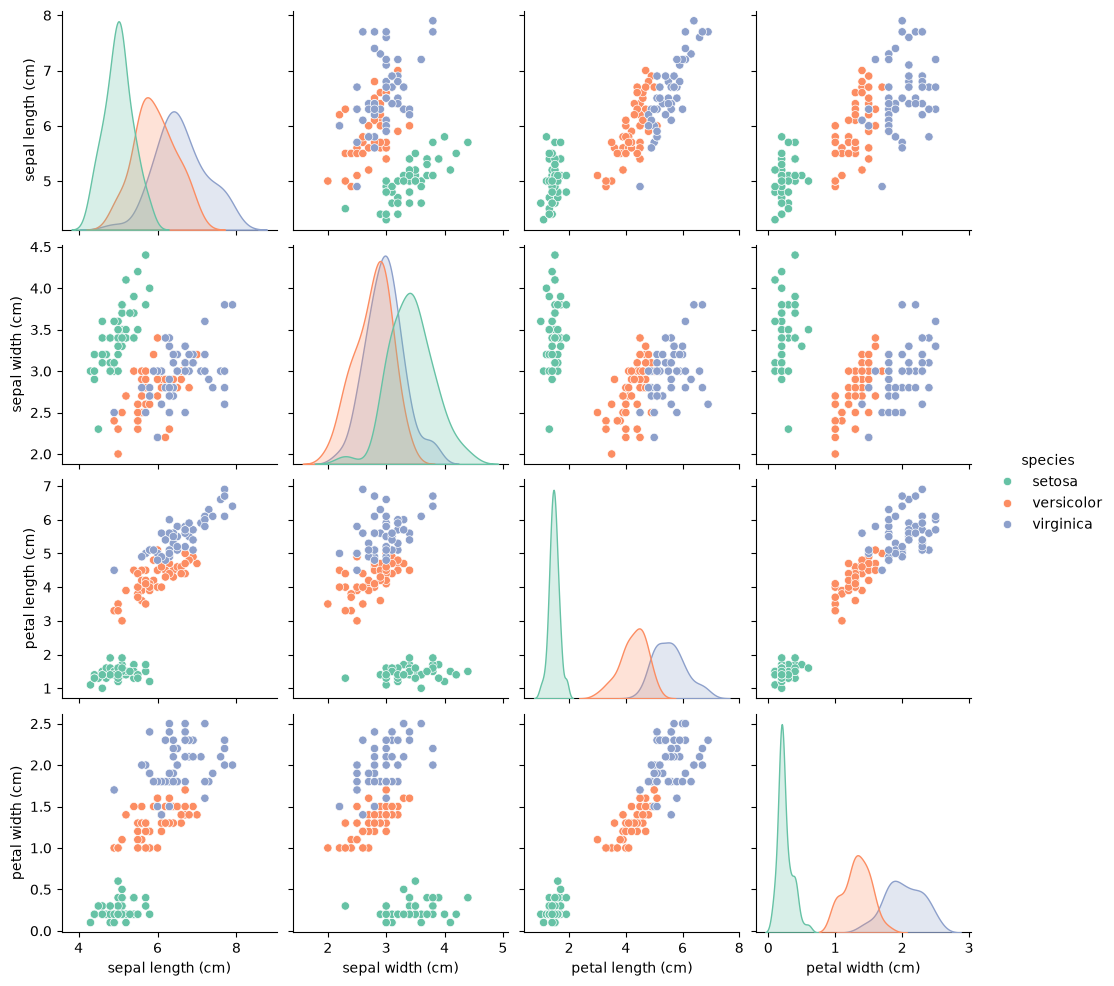

In [5]:
feature_cols = [c for c in data.columns if c.lower() not in ['id']]
sns.pairplot(data[feature_cols], hue=target_col, palette='Set2')
plt.show()

## Langkah 4 - Preprocessing dan Pembagian Data (70:30)

In [6]:
X = data[[c for c in data.columns if c.lower() not in ['id', target_col]]]
y = data[target_col]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print(f'Ukuran data latih: {X_train.shape}, data uji: {X_test.shape}')

Ukuran data latih: (105, 4), data uji: (45, 4)


## Langkah 5 - Membangun Model kNN (k = 3)

In [7]:
knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",3
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[object](3,)","['setosa','versicolor','virginica']"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


## Langkah 6 - Evaluasi Model kNN

In [8]:
y_pred = knn.predict(X_test)
print(f'Akurasi Model (k=3): {accuracy_score(y_test, y_pred):.4f}')
print('\nConfusion Matrix:\n', confusion_matrix(y_test, y_pred))
print('\nLaporan Klasifikasi:\n', classification_report(y_test, y_pred))

Akurasi Model (k=3): 0.9111

Confusion Matrix:
 [[15  0  0]
 [ 0 15  0]
 [ 0  4 11]]

Laporan Klasifikasi:
               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.79      1.00      0.88        15
   virginica       1.00      0.73      0.85        15

    accuracy                           0.91        45
   macro avg       0.93      0.91      0.91        45
weighted avg       0.93      0.91      0.91        45



## Langkah 7 - Eksperimen Nilai K Terbaik (k = 1 s.d. 10)

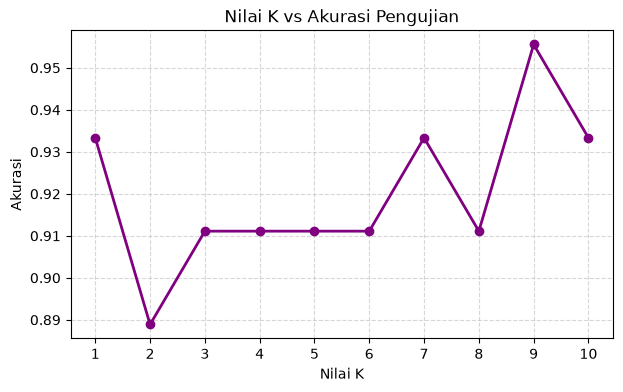

k =  1 -> Akurasi = 93.33%
k =  2 -> Akurasi = 88.89%
k =  3 -> Akurasi = 91.11%
k =  4 -> Akurasi = 91.11%
k =  5 -> Akurasi = 91.11%
k =  6 -> Akurasi = 91.11%
k =  7 -> Akurasi = 93.33%
k =  8 -> Akurasi = 91.11%
k =  9 -> Akurasi = 95.56%
k = 10 -> Akurasi = 93.33%


In [9]:
acc = []
k_range = range(1, 11)
for k in k_range:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train, y_train)
    acc.append(model.score(X_test, y_test))

plt.figure(figsize=(7, 4))
plt.plot(k_range, acc, marker='o', color='purple', linewidth=2)
plt.title('Nilai K vs Akurasi Pengujian')
plt.xlabel('Nilai K')
plt.ylabel('Akurasi')
plt.xticks(k_range)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

for k_val, a in zip(k_range, acc):
    print(f'k = {k_val:2d} -> Akurasi = {a*100:.2f}%')